# Result analysis

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import load_case, compute_errors, print_err_mean_std, err_kde_plot, time_kde_plot, err_pointwise_plot, print_exec_times, plot_velocity

import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colors import ListedColormap
import seaborn as sns

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "text.latex.preamble": r"\usepackage{amsmath}",
})

miktex_bin = r"C:\Users\gkova\AppData\Local\Programs\MiKTeX\miktex\bin\x64"

if miktex_bin not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + miktex_bin

In [ ]:
# Specify a results directory
RESULT_DIR = "./results/2026-03-26_18_12"

# Load results
results = load_case(RESULT_DIR)

## Global Errors

#### L1 Norm

In [3]:
errors = compute_errors(results, norm="1")
print_err_mean_std(errors)

numeric divergence = 0.03951243289828694 +- 0.25429684497715005

u poisson error = 0.04669060984750274 +- 0.02672838833243597
p poisson error = 0.2861846091161707 +- 0.24233407420100708
poisson divergence error = 0.08138229493159868 +- 0.27259858377801005

u full error = 0.22271880633327892 +- 0.04468607583203961
p full error = 0.7625084452002673 +- 0.08104406701639102
full divergence error = 0.1547384018080805 +- 0.2715833098434162


#### L2 Norm

In [4]:
errors = compute_errors(results, norm="2")
print_err_mean_std(errors)

numeric divergence = 0.06622811771884383 +- 1.5803030735144792

u poisson error = 0.04717643111864558 +- 0.028722578761912577
p poisson error = 0.2861846091161707 +- 0.24233407420100708
poisson divergence error = 0.08093306580611066 +- 1.785263972257556

u full error = 0.20568271541756208 +- 0.0421082657052584
p full error = 0.7625084452002673 +- 0.08104406701639102
full divergence error = 0.09770146717964291 +- 0.8191247403354251


#### Infinity Norm

In [5]:
errors = compute_errors(results, norm="inf")
print_err_mean_std(errors)

numeric divergence = 0.03951243289828694 +- 0.25429684497715005

u poisson error = 0.047155507621523735 +- 0.02966274721284347
p poisson error = 0.2861846091161707 +- 0.24233407420100708
poisson divergence error = 0.08138229493159868 +- 0.27259858377801005

u full error = 0.1944683720237823 +- 0.03982675420472589
p full error = 0.7625084452002673 +- 0.08104406701639102
full divergence error = 0.1547384018080805 +- 0.2715833098434162


### Comparison plot

C:\Users\gkova\AppData\Local\Temp\ipykernel_28860\49311338.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 1])


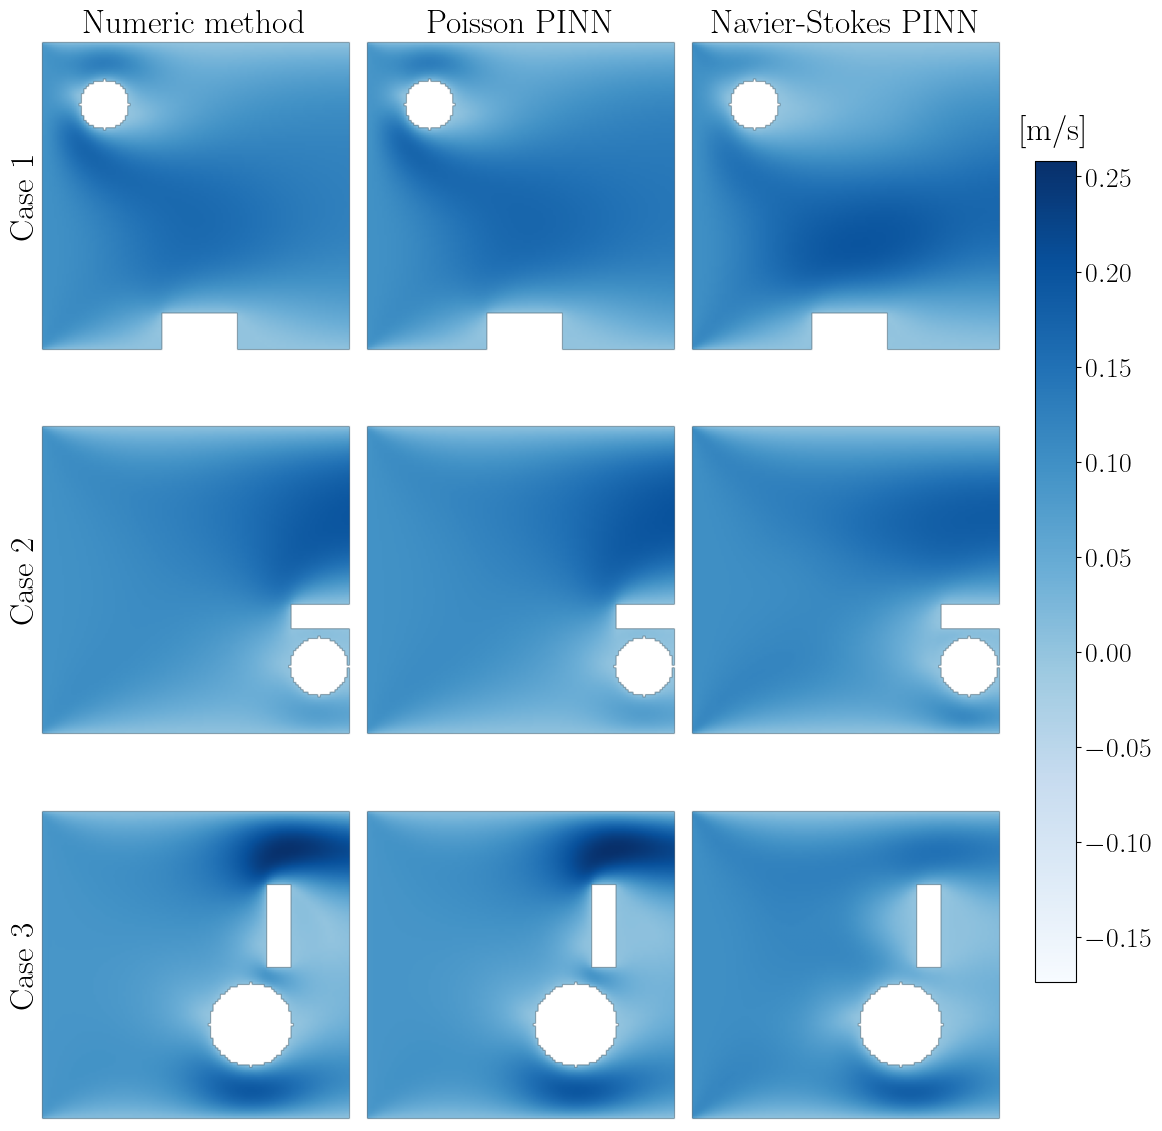

In [ ]:
n_cases = 3

cmap = "Blues"

vmin = []
vmax = []

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    vmin.append(np.min([Un.min(), Vn.min(), Up.min(), Vp.min(), Uf.min(), Vf.min()]))
    vmax.append(np.max([Un.max(), Vn.max(), Up.max(), Vp.max(), Uf.max(), Vf.max()]))

vmin = np.min(vmin)
vmax = np.max(vmax)

fig, ax = plt.subplots(figsize=(12, 12), nrows=n_cases, ncols=3)

bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    boundary = np.array(results["boundaries"][i], dtype=float)

    height, width = np.shape(results["u_numeric"][i])[0], np.shape(results["u_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, np.linspace(0, height, height) + 0.5)

    ax[i, 0].imshow(np.sqrt(Un ** 2 + Vn ** 2), vmin=vmin, vmax=vmax, cmap=cmap)
    ax[i, 1].imshow(np.sqrt(Up ** 2 + Vp ** 2), vmin=vmin, vmax=vmax, cmap=cmap)
    im = ax[i, 2].imshow(np.sqrt(Uf ** 2 + Vf ** 2), vmin=vmin, vmax=vmax, cmap=cmap)

    for j in range(3):
        ax[i, j].imshow(boundary, cmap=bw_map)

    ax[i, 0].annotate(f"Case {i+1}", xy=(-0, 0.5), xycoords="axes fraction", rotation=90, va="center", ha="right", fontsize=24)

    for j in range(3):
        ax[i, j].axis("off")

cbar = fig.colorbar(im, ax=ax[:, 2])
cbar.ax.tick_params(labelsize=20)
cbar.ax.set_title(r"[m/s]", fontsize=24, pad=15)

ax[0, 0].set_title("Numeric method", fontsize=24)
ax[0, 1].set_title("Poisson PINN", fontsize=24)
ax[0, 2].set_title("Navier-Stokes PINN", fontsize=24)

plt.tight_layout(rect=[0, 0, 0.85, 1])

plt.savefig("flow_examples.pdf")

### Comparison plot (relative errors)

C:\Users\gkova\AppData\Local\Temp\ipykernel_24904\1268734789.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 1])


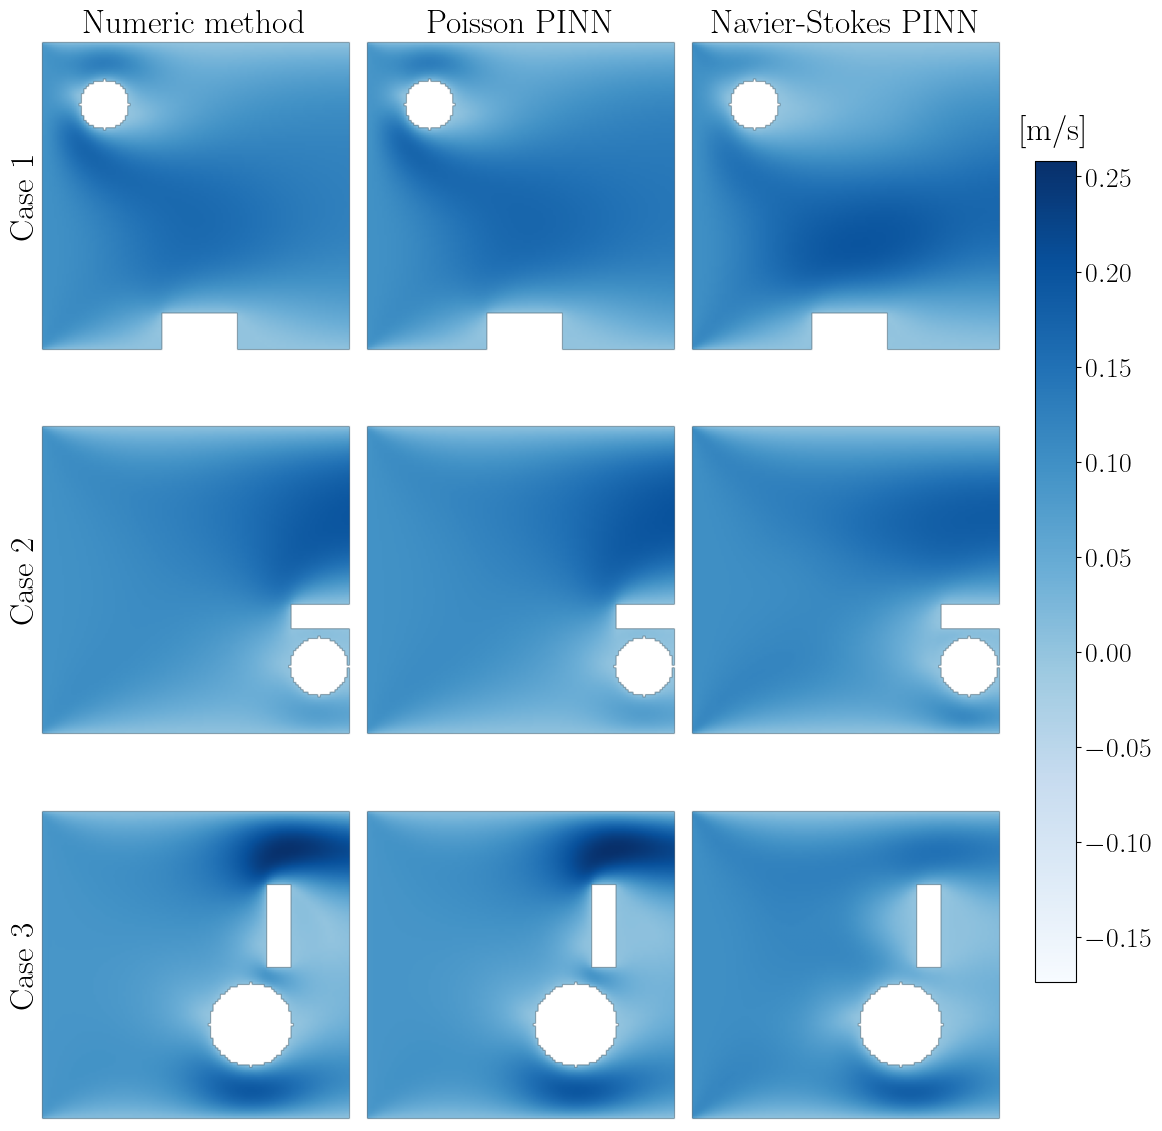

In [ ]:
n_cases = 3

cmap = "Blues"

vmin = []
vmax = []

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    vmin.append(np.min([Un.min(), Vn.min(), Up.min(), Vp.min(), Uf.min(), Vf.min()]))
    vmax.append(np.max([Un.max(), Vn.max(), Up.max(), Vp.max(), Uf.max(), Vf.max()]))

vmin = np.min(vmin)
vmax = np.max(vmax)

fig, ax = plt.subplots(figsize=(12, 12), nrows=n_cases, ncols=3)

bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    boundary = np.array(results["boundaries"][i], dtype=float)

    height, width = np.shape(results["u_numeric"][i])[0], np.shape(results["u_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, np.linspace(0, height, height) + 0.5)
    

    ax[i, 0].imshow(np.sqrt(Un ** 2 + Vn ** 2), vmin=vmin, vmax=vmax, cmap=cmap)
    ax[i, 1].imshow(np.sqrt(Up ** 2 + Vp ** 2), vmin=vmin, vmax=vmax, cmap=cmap)
    im = ax[i, 2].imshow(np.sqrt(Uf ** 2 + Vf ** 2), vmin=vmin, vmax=vmax, cmap=cmap)

    for j in range(3):
        ax[i, j].imshow(boundary, cmap=bw_map)

    ax[i, 0].annotate(f"Case {i+1}", xy=(-0, 0.5), xycoords="axes fraction", rotation=90, va="center", ha="right", fontsize=24)
    
    for j in range(3):
        ax[i, j].axis("off")

cbar = fig.colorbar(im, ax=ax[:, 2])
cbar.ax.tick_params(labelsize=20)
cbar.ax.set_title(r"[m/s]", fontsize=24, pad=15)

ax[0, 0].set_title("Numeric method", fontsize=24)
ax[0, 1].set_title("Poisson PINN", fontsize=24)
ax[0, 2].set_title("Navier-Stokes PINN", fontsize=24)

plt.tight_layout(rect=[0, 0, 0.85, 1])

plt.savefig("flow_examples_relative_err.pdf")

### Comparison plot (pressure)

C:\Users\gkova\AppData\Local\Temp\ipykernel_28860\336659275.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 1])


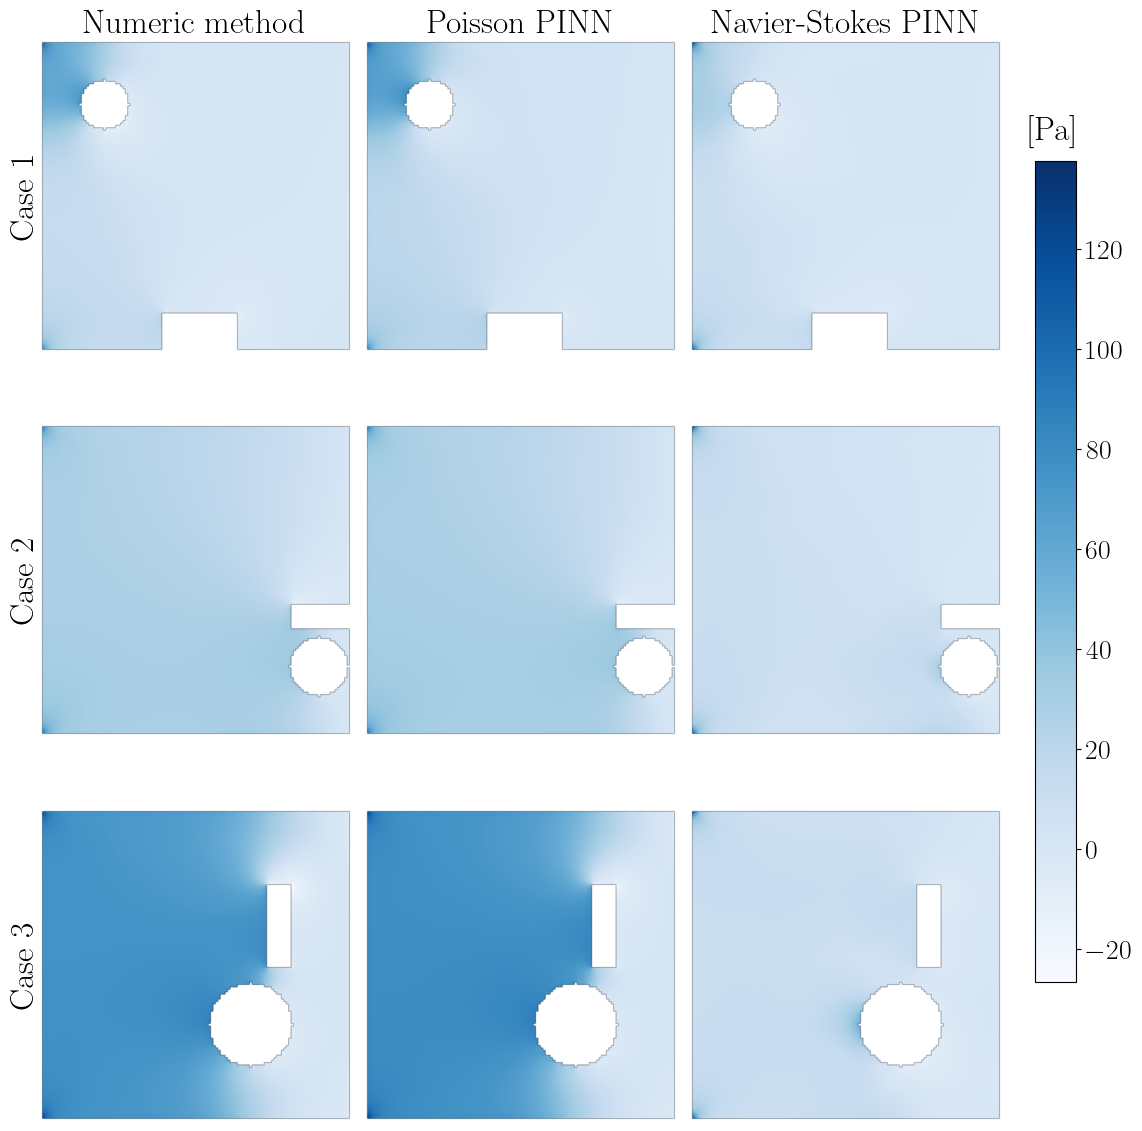

In [ ]:
n_cases = 3

cmap = "Blues"

vmin = []
vmax = []

for i in range(n_cases):
    Pn = np.array(results["p_numeric"][i], dtype=float)
    Pp = np.array(results["p_poisson"][i], dtype=float)
    Pf = np.array(results["p_full"][i], dtype=float)

    vmin.append(np.min([Pn.min(), Pp.min(), Pf.min()]))
    vmax.append(np.max([Pn.max(), Pp.max(), Pf.max()]))

vmin = np.min(vmin)
vmax = np.max(vmax)

fig, ax = plt.subplots(figsize=(12, 12), nrows=n_cases, ncols=3)

bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(n_cases):
    Pn = np.array(results["p_numeric"][i], dtype=float)
    Pp = np.array(results["p_poisson"][i], dtype=float)
    Pf = np.array(results["p_full"][i], dtype=float)

    boundary = np.array(results["boundaries"][i], dtype=float)

    height, width = np.shape(results["p_numeric"][i])[0], np.shape(results["p_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, 
                       np.linspace(0, height, height) + 0.5)
    

    ax[i, 0].imshow(Pn, vmin=vmin, vmax=vmax, cmap=cmap)
    ax[i, 1].imshow(Pp, vmin=vmin, vmax=vmax, cmap=cmap)
    im = ax[i, 2].imshow(Pf, vmin=vmin, vmax=vmax, cmap=cmap)

    for j in range(3):
        ax[i, j].imshow(boundary, cmap=bw_map)

    ax[i, 0].annotate(f"Case {i+1}", xy=(-0, 0.5), xycoords="axes fraction", rotation=90, va="center", ha="right", fontsize=24)

    for j in range(3):
        ax[i, j].axis("off")

cbar = fig.colorbar(im, ax=ax[:, 2])
cbar.ax.tick_params(labelsize=20)
cbar.ax.set_title(r"[Pa]", fontsize=24, pad=15)

ax[0, 0].set_title("Numeric method", fontsize=24)
ax[0, 1].set_title("Poisson PINN", fontsize=24)
ax[0, 2].set_title("Navier-Stokes PINN", fontsize=24)

plt.tight_layout(rect=[0, 0, 0.85, 1])

plt.savefig("flow_examples_pressure.pdf")

### Pointwise errors

#### L2 Norm

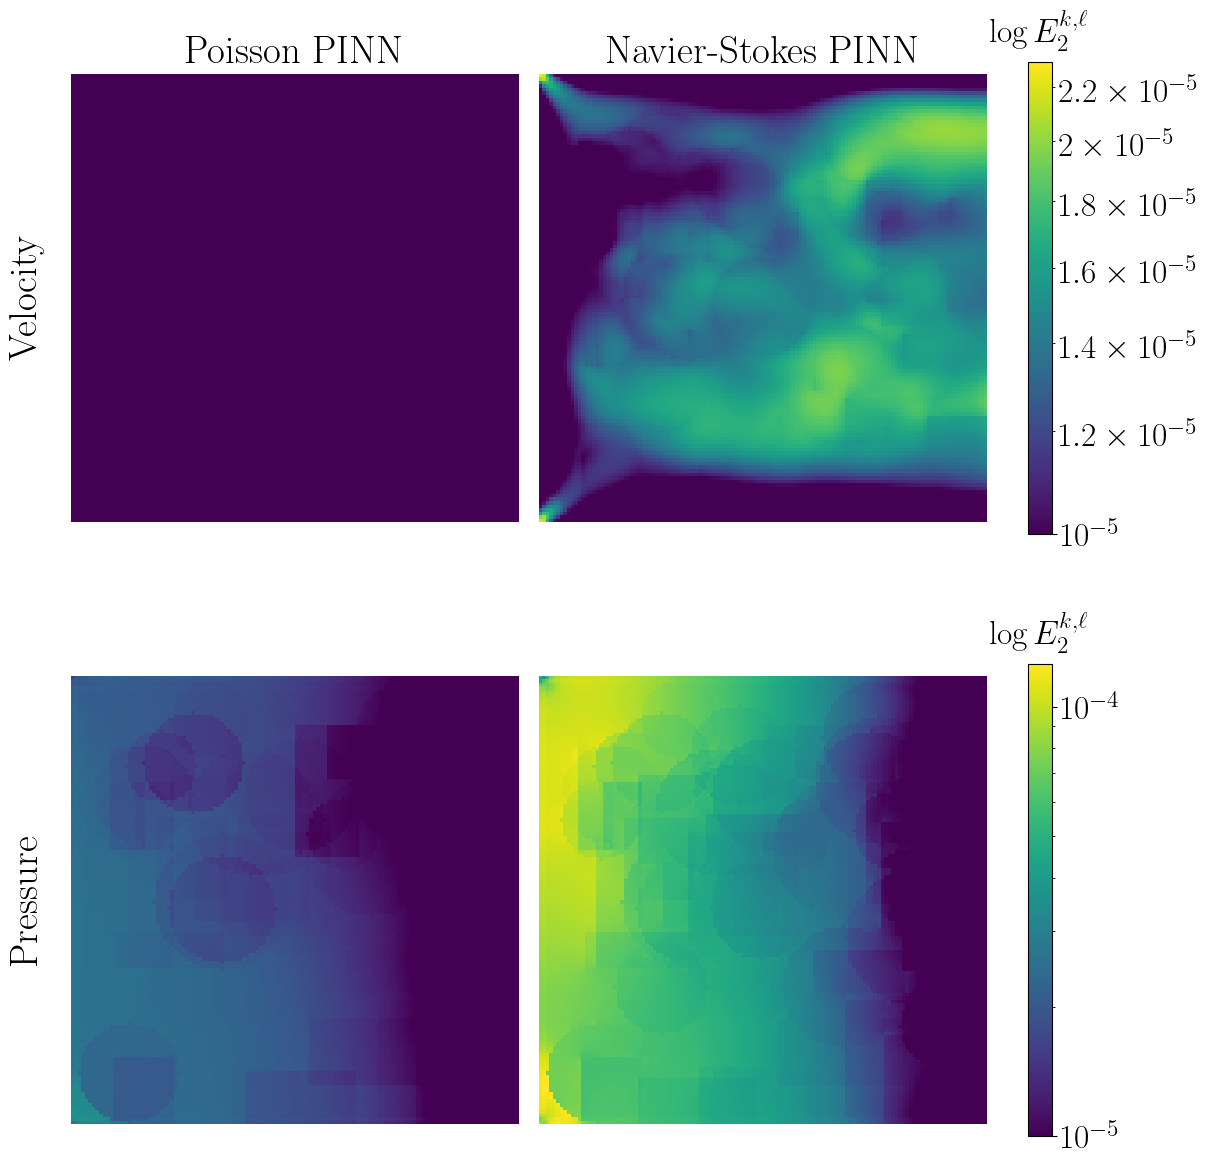

In [11]:
importlib.reload(analysis_functions)

errors = analysis_functions.compute_errors(results, norm="2")
analysis_functions.err_pointwise_plot(errors, title="mean_err_log.pdf")

### Single case errors

#### L1 norm

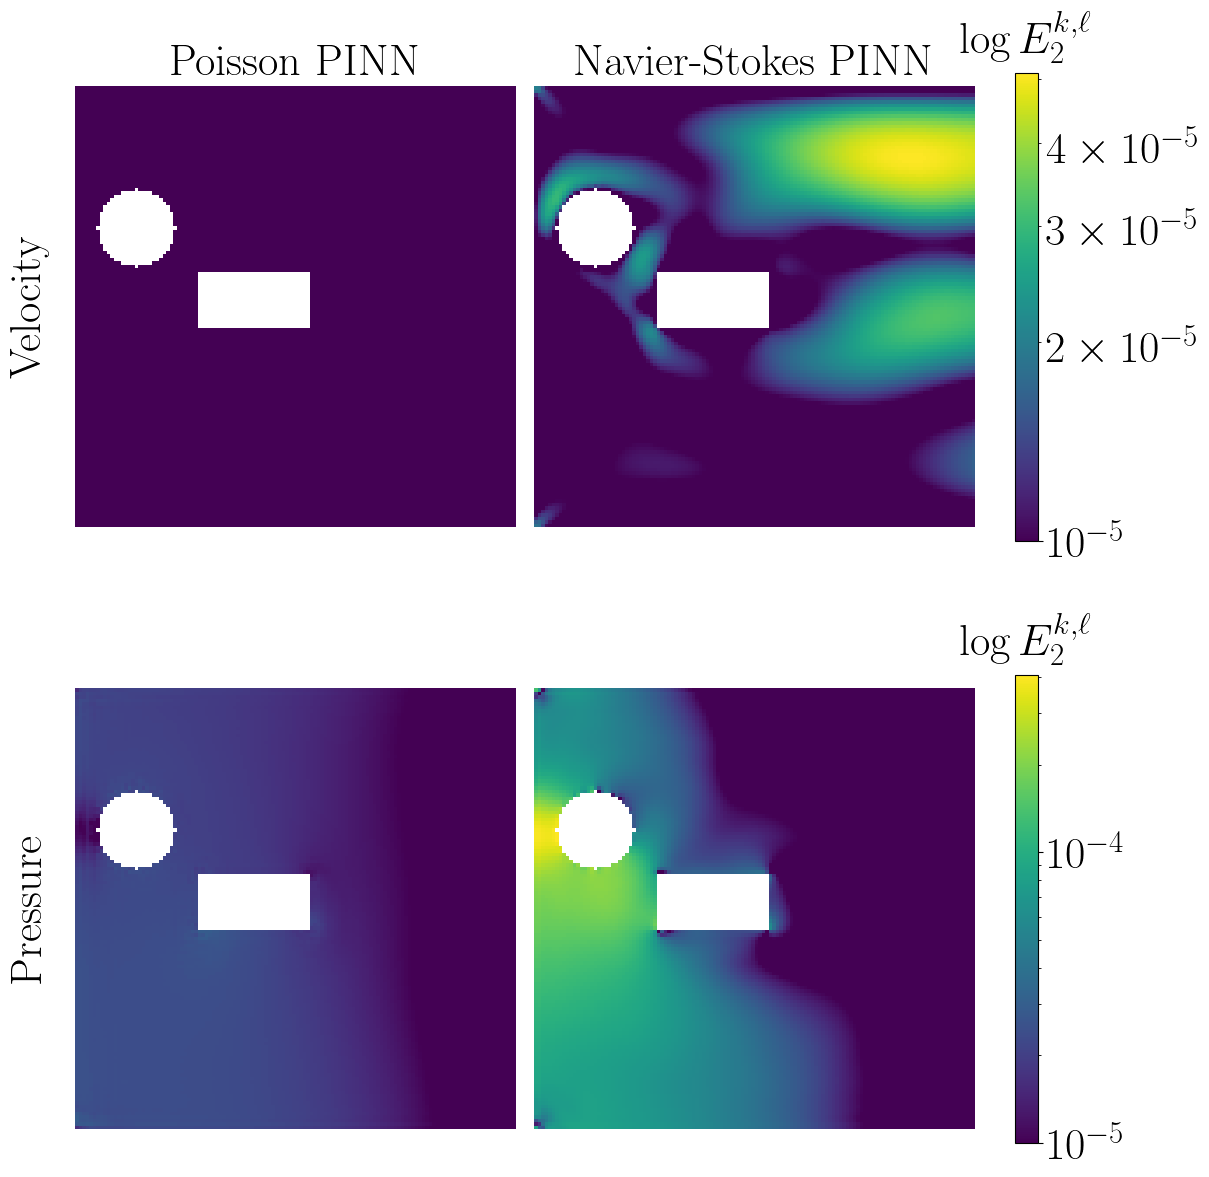

In [5]:
importlib.reload(analysis_functions)

case_num = 7

errors = analysis_functions.compute_errors(results, norm="2")
for k in errors.keys():
    errors[k] = [errors[k][case_num]]

analysis_functions.err_pointwise_plot(errors, title=f"err_case_{case_num}_log.pdf")

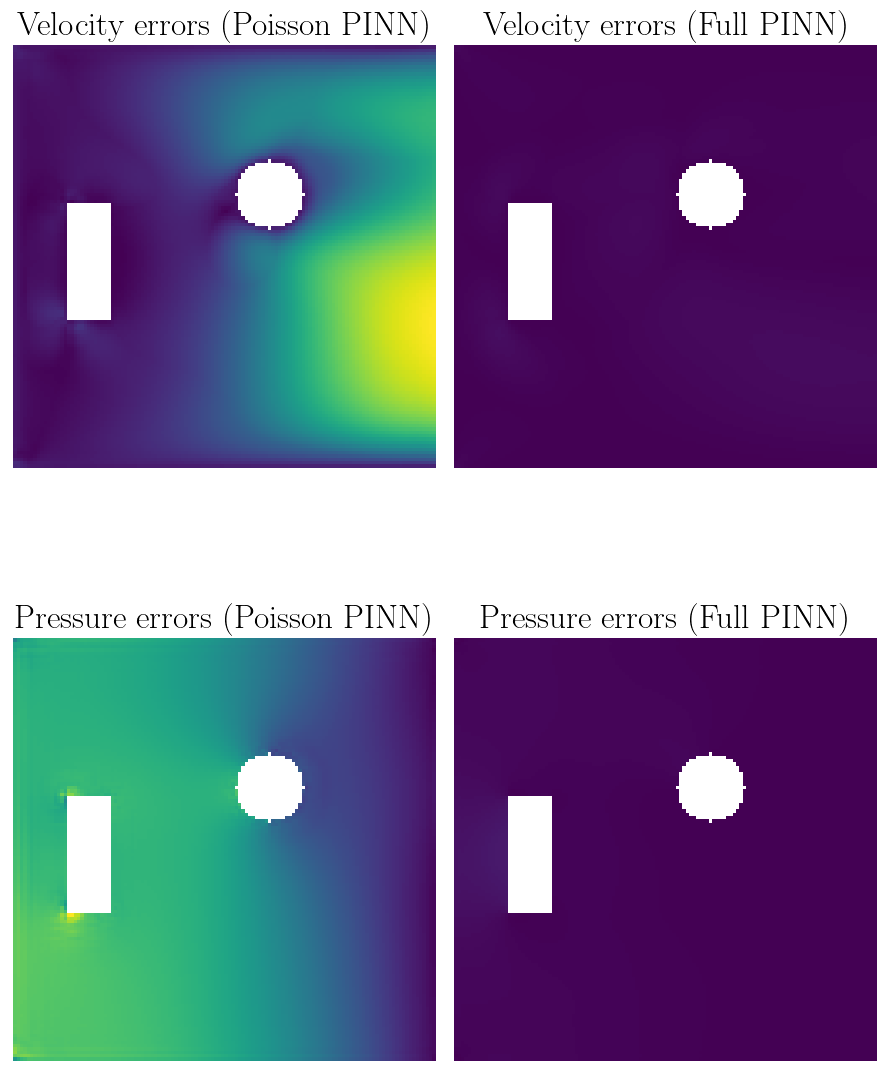

In [ ]:
case_num = 3

importlib.reload(analysis_functions)

errors = analysis_functions.compute_errors(results, norm="1")

fig, ax = plt.subplots(figsize=(12, 12), nrows=2, ncols=2)
ax = ax.flatten()

u_denom = np.array(errors["u_denominator"])
p_denom = np.array(errors["p_denominator"])

bound = np.array(errors["boundaries"])

u_poisson = np.array(errors["u_err_poisson"], dtype=float) * (1 - bound) / (u_denom[:, None, None] * np.ones(np.array(errors["u_err_poisson"], dtype=float).shape))
p_poisson = np.array(errors["p_err_poisson"], dtype=float) * (1 - bound) / (u_denom[:, None, None] * np.ones(np.array(errors["p_err_poisson"], dtype=float).shape))

u_full = np.array(errors["u_err_full"], dtype=float) * (1 - bound) / (p_denom[:, None, None] * np.ones(np.array(errors["u_err_poisson"], dtype=float).shape))
p_full = np.array(errors["p_err_full"], dtype=float) * (1 - bound) / (p_denom[:, None, None] * np.ones(np.array(errors["p_err_poisson"], dtype=float).shape))

u_poisson = u_poisson[case_num]
p_poisson = p_poisson[case_num]
u_full = u_full[case_num]
p_full = p_full[case_num]

umin = min(u_poisson.min(), u_full.min())
umax = max(u_poisson.max(), u_full.max())

pmin = min(p_poisson.min(), p_full.min())
pmax = max(p_poisson.max(), p_full.max())

im0 = ax[0].imshow(u_poisson, vmin=umin, vmax=umax)
im1 = ax[1].imshow(u_full, vmin=umin, vmax=umax)
im2 = ax[2].imshow(p_poisson, vmin=pmin, vmax=pmax)
im3 = ax[3].imshow(p_full, vmin=pmin, vmax=pmax)

bw_map = ListedColormap([(0, 0, 0, 0), (1, 1, 1, 1)])

for i in range(0, 4):
    ax[i].imshow(bound[case_num], cmap=bw_map)
    ax[i].axis("off")

ax[0].set_title("Velocity errors (Poisson PINN)", fontsize=24)
ax[1].set_title("Velocity errors (Full PINN)", fontsize=24)
ax[2].set_title("Pressure errors (Poisson PINN)", fontsize=24)
ax[3].set_title("Pressure errors (Full PINN)", fontsize=24)

plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.show()


### Divergence errors

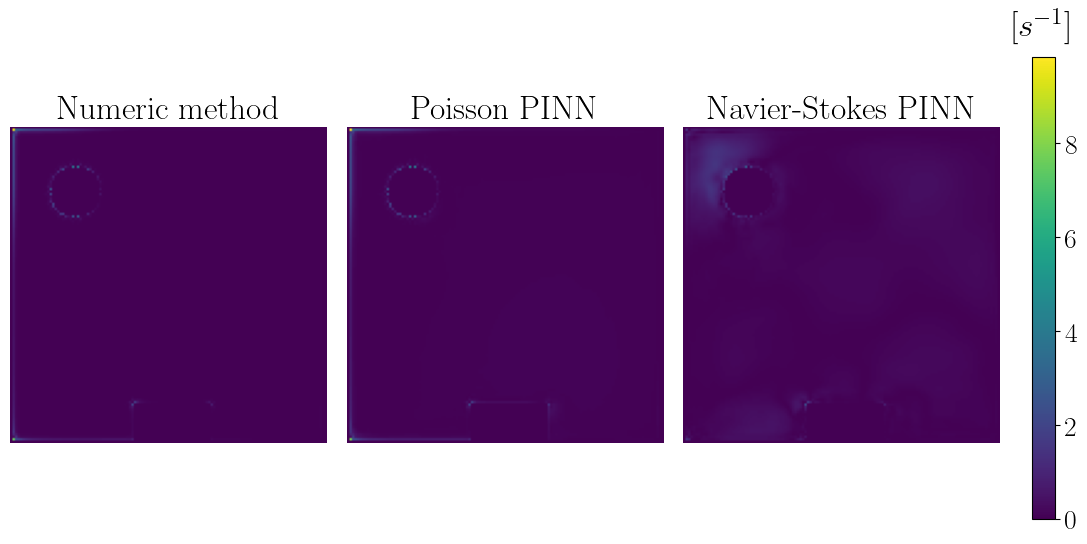

In [95]:
importlib.reload(analysis_functions)

case_num = 0

errors = analysis_functions.compute_errors(results, norm="1")
for k in errors.keys():
    errors[k] = [errors[k][case_num]]

analysis_functions.err_divergence_plot(errors, title=f"div_case_{case_num}.pdf")

c:\Users\gkova\Documents\masters_thesis\src\analysis\analysis_functions.py:340: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.85, 1])


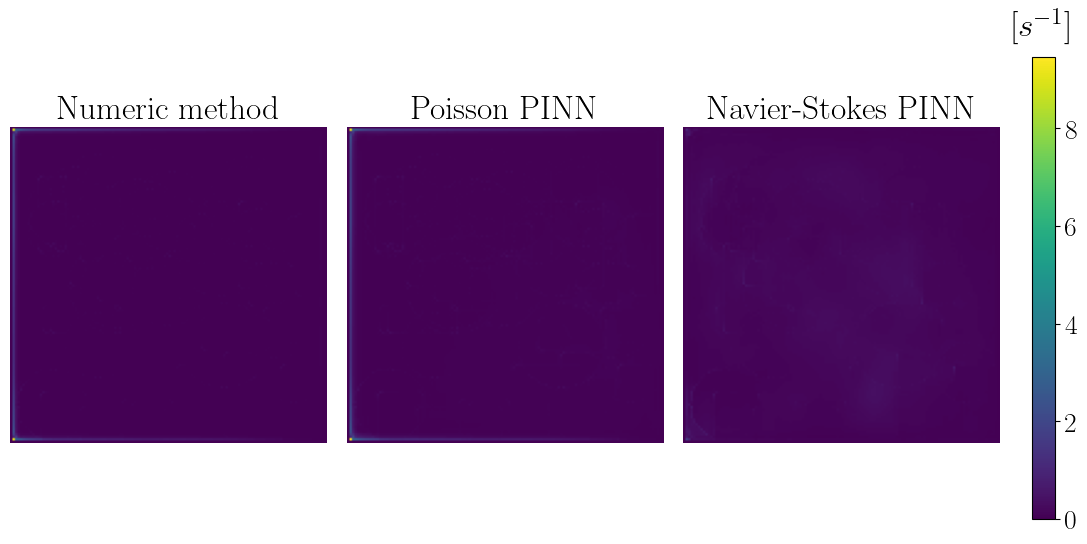

In [97]:
importlib.reload(analysis_functions)

errors = analysis_functions.compute_errors(results, norm="1")

analysis_functions.err_divergence_plot(errors, title=f"div_mean.pdf")

### Histogram of errors

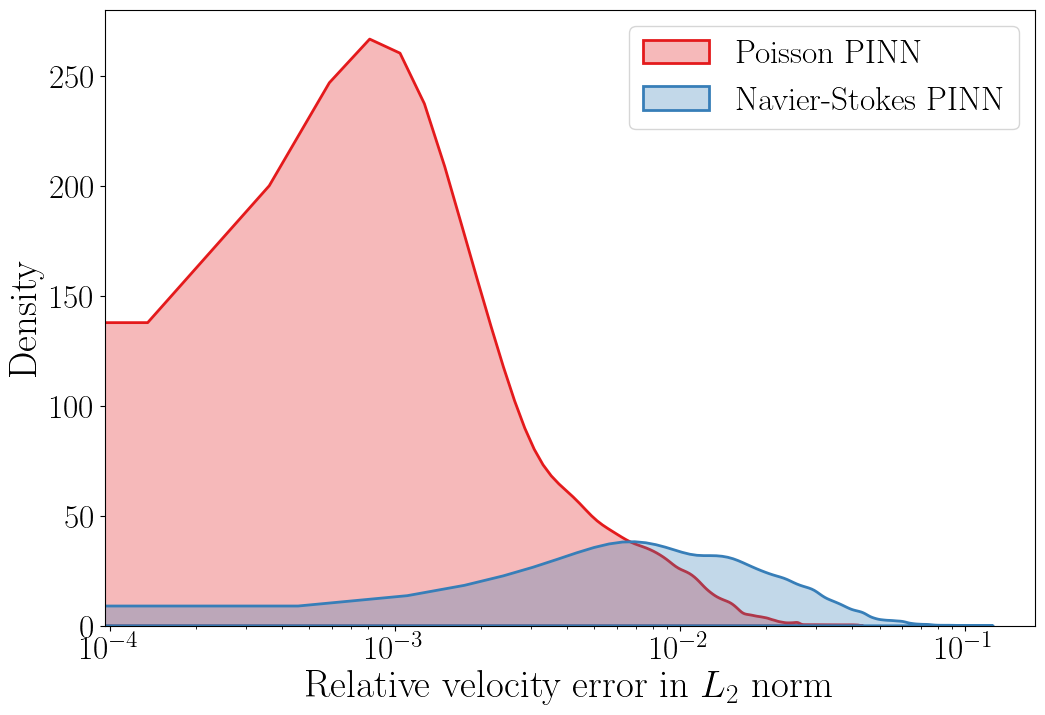

In [9]:
errors_poisson = np.array([])
errors_full = np.array([])

errors = compute_errors(results, norm="2")

for case_num in range(0, 25):
    bound = errors["boundaries"][case_num]

    errors_poisson = np.concatenate([errors_poisson, errors["u_err_poisson"][case_num][bound != 1].flatten()])
    errors_full = np.concatenate([errors_full, errors["u_err_full"][case_num][bound != 1].flatten()])

# errors = np.array(errors)
fig, ax = plt.subplots(figsize=(12, 8), nrows=1, ncols=1)

sns.kdeplot(errors_poisson, label="Poisson PINN", color="#e41a1c", fill=True, alpha=0.3, linewidth=2, ax=ax)
sns.kdeplot(errors_full, label="Navier-Stokes PINN", color="#377eb8", fill=True, alpha=0.3, linewidth=2, ax=ax)

ax.set_xlabel("Relative velocity error in $L_2$ norm", fontsize=28)
ax.set_ylabel("Density", fontsize=28)

ax.tick_params(axis='both', which='major', labelsize=24)

ax.set_xscale("log")

plt.legend(fontsize=24)

plt.savefig("kde_velocity.pdf")

plt.show()

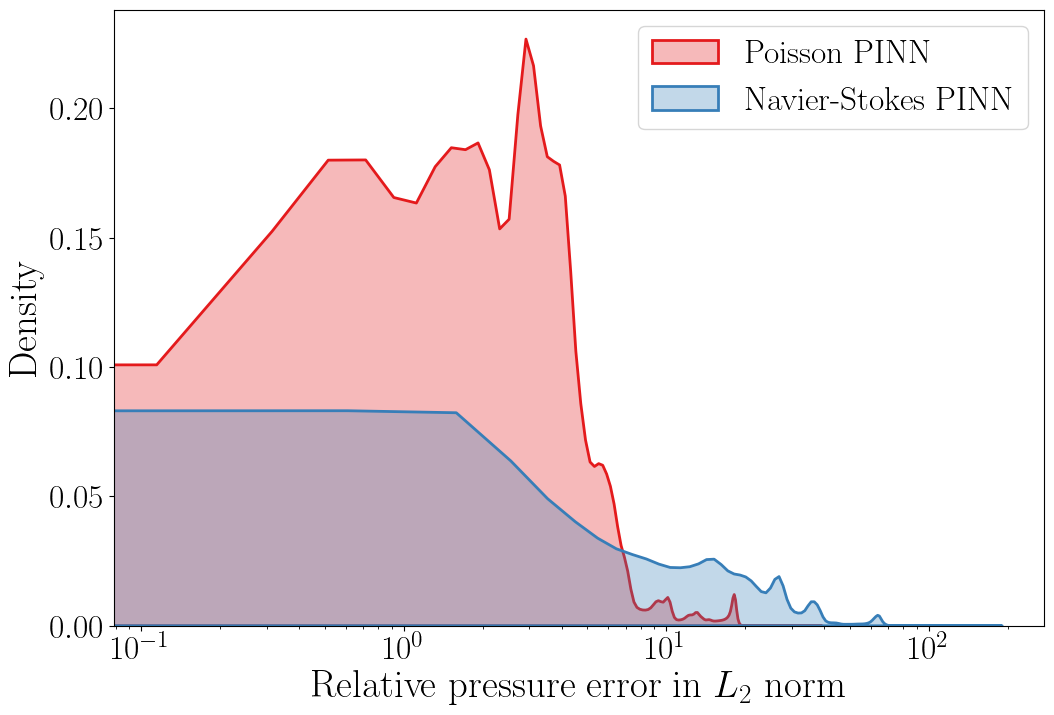

In [10]:
errors_poisson = np.array([])
errors_full = np.array([])

errors = compute_errors(results, norm="2")

for case_num in range(0, 25):
    bound = errors["boundaries"][case_num]

    errors_poisson = np.concatenate([errors_poisson, errors["p_err_poisson"][case_num][bound != 1].flatten()])
    errors_full = np.concatenate([errors_full, errors["p_err_full"][case_num][bound != 1].flatten()])

# errors = np.array(errors)
fig, ax = plt.subplots(figsize=(12, 8), nrows=1, ncols=1)

sns.kdeplot(errors_poisson, label="Poisson PINN", color="#e41a1c", fill=True, alpha=0.3, linewidth=2, ax=ax)
sns.kdeplot(errors_full, label="Navier-Stokes PINN", color="#377eb8", fill=True, alpha=0.3, linewidth=2, ax=ax)

ax.set_xlabel("Relative pressure error in $L_2$ norm", fontsize=28)
ax.set_ylabel("Density", fontsize=28)

ax.tick_params(axis='both', which='major', labelsize=24)

ax.set_xscale("log")

plt.legend(fontsize=24)

plt.savefig("kde_pressure.pdf")

plt.show()

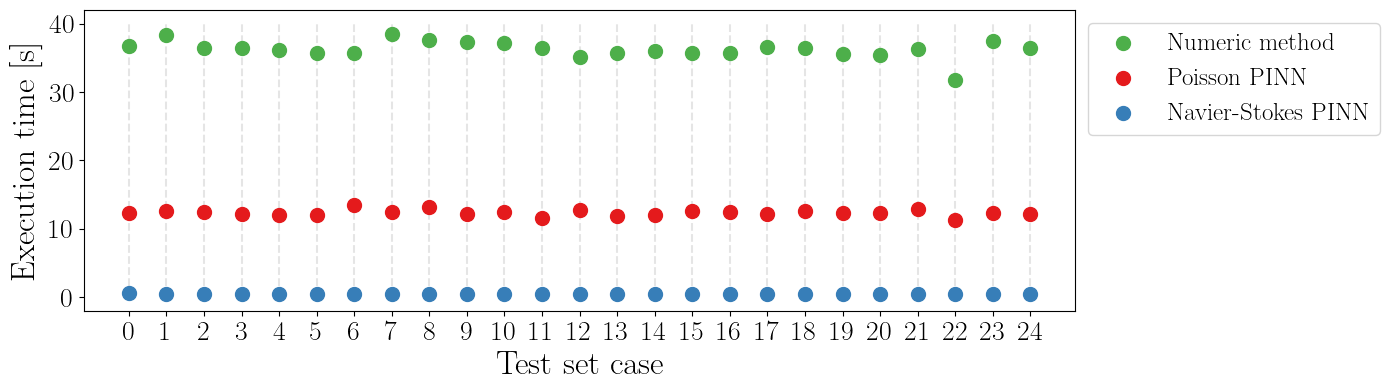

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4))

idx = np.arange(len(results["exec_times"]["numeric"]))

ax.vlines(idx, ymin=0, ymax=40, color="black", alpha=0.1, linestyles="--", zorder=0)

ax.scatter(idx, results["exec_times"]["numeric"], color="#4daf4a", label="Numeric method", s=100)
ax.scatter(idx, results["exec_times"]["poisson"], color="#e41a1c", label="Poisson PINN", s=100)
ax.scatter(idx, results["exec_times"]["full"], color="#377eb8", label="Navier-Stokes PINN", s=100)

width = 0.3

ax.set_xticks(idx)
ax.set_xticklabels(idx)
ax.tick_params(axis='both', which='major', labelsize=20)

ax.set_xlabel("Test set case", fontsize=24)
ax.set_ylabel("Execution time [s]", fontsize=24)

ax.legend(fontsize=18, loc='upper left', bbox_to_anchor=(1, 1), frameon=True)

plt.tight_layout()

plt.savefig("exec_times.pdf")

In [92]:
print("Execution times")
print(f"numeric = {results["exec_times"]["numeric"].mean()} +- {results["exec_times"]["numeric"].std()}")
print(f"poisson = {results["exec_times"]["poisson"].mean()} +- {results["exec_times"]["poisson"].std()}")
print(f"full = {results["exec_times"]["full"].mean()} +- {results["exec_times"]["full"].std()}")

Execution times
numeric = 36.26456961631775 +- 1.281128798792494
poisson = 12.326171684265137 +- 0.4623323086222934
full = 0.428245849609375 +- 0.03980697251253322
